
# 05 — Model Evaluation and Kaggle Submission

## 5.1 Objectives

This notebook evaluates the saved ResNet18 baseline and verifies its Kaggle prediction file.

The objectives are to:

- Summarise overall and class-level validation performance.
- Visualise the confusion matrix and identify common classification errors.
- Verify the submission CSV against Kaggle's sample format.
- Record the observed leaderboard outcome.
- Discuss generalisation and evaluation limitations.


## 5.2 Load saved evaluation evidence

In [2]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data"
ARTIFACTS = ROOT / "artifacts" / "baseline"

config = json.loads((ARTIFACTS / "config.json").read_text())
metrics = json.loads((ARTIFACTS / "metrics.json").read_text())
history = pd.read_csv(ARTIFACTS / "history.csv")

classes = config["classes"]
report = pd.DataFrame(metrics["classification_report"]).T

best_epoch = history.loc[history["validation_loss"].idxmin(), "epoch"]

print(f"Validation accuracy: {metrics['validation_accuracy']:.2%}")
print(f"Recorded epochs: {len(history)}")
print(f"Best checkpoint epoch by validation loss: {best_epoch}")

Validation accuracy: 75.35%
Recorded epochs: 2
Best checkpoint epoch by validation loss: 2


## 5.3 Classification performance

In [3]:
overall = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Weighted F1",
        ],
        "Value": [
            metrics["validation_accuracy"],
            report.loc["macro avg", "precision"],
            report.loc["macro avg", "recall"],
            report.loc["macro avg", "f1-score"],
            report.loc["weighted avg", "f1-score"],
        ],
    }
)

display(overall.style.format({"Value": "{:.2%}"}))

display(report.loc[classes, ["precision", "recall", "f1-score", "support"]].round(3))

,Metric,Value
0,Accuracy,75.35%
1,Macro Precision,74.99%
2,Macro Recall,71.39%
3,Macro F1,70.53%
4,Weighted F1,73.72%


,precision,recall,f1-score,support
CatEye,0.827,0.966,0.891,2777.0
CatFace,0.991,0.890,0.938,1389.0
CatMouth,0.620,0.219,0.324,1388.0
CatNose,0.513,0.799,0.625,1388.0
DogEye,0.840,0.843,0.842,2316.0
DogFace,0.968,0.890,0.928,1158.0
DogMouth,0.702,0.351,0.468,1158.0
DogNose,0.538,0.752,0.628,1158.0


## 5.4 Confusion matrix

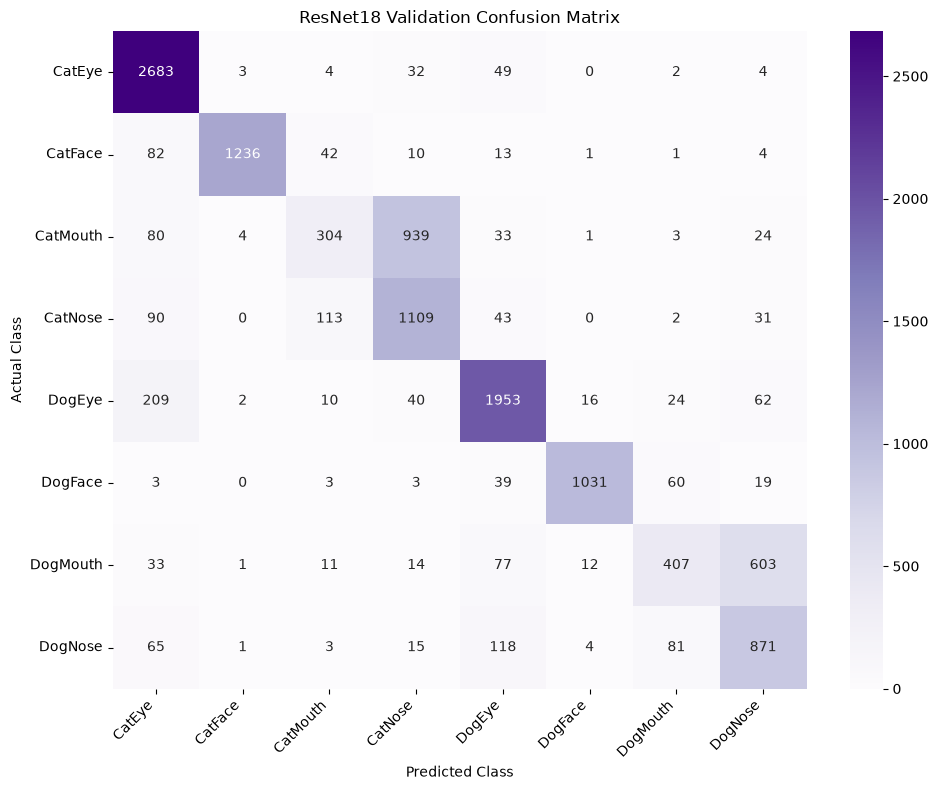

In [4]:
cm = pd.DataFrame(
    metrics["confusion_matrix"],
    index=classes,
    columns=classes,
)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=classes,
    yticklabels=classes,
    ax=ax,
)

ax.set(
    title="ResNet18 Validation Confusion Matrix",
    xlabel="Predicted Class",
    ylabel="Actual Class",
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

assert cm.to_numpy().sum() == config["validation_samples"]

## 5.5 Kaggle submission verification

In [5]:
sample = pd.read_csv(DATA / "sample_submission.csv", dtype={"image_id": str})

submission_path = ARTIFACTS / "submission.csv"
submission = pd.read_csv(submission_path, dtype={"image_id": str})

assert list(submission.columns) == list(sample.columns)
assert len(submission) == len(sample) == 29_443

assert submission.iloc[:, 0].tolist() == sample.iloc[:, 0].tolist()

assert submission.iloc[:, 1].isin(classes).all()
assert not submission.isna().any().any()

sha256 = hashlib.sha256(submission_path.read_bytes()).hexdigest()

print("Submission verification passed.")
print("Prediction rows:", len(submission))
print("SHA256:", sha256)

display(submission.head())

Submission verification passed.
Prediction rows: 29443
SHA256: e42b904467b03229a804dedfe2d2f35273fdea23493e987e596fb9afc733fbf8


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth



## 5.6 Kaggle Competition Result

A baseline prediction file was successfully submitted to the ENGE707 Kaggle competition on 25 October 2026.

The submission was observed at 70th place on the leaderboard.

The exact public leaderboard score and observation timestamp should be recorded from Kaggle's submission history and accompanying screenshot.

The Kaggle result and local validation accuracy represent evaluations on different image sets and should not be treated as interchangeable.



## 5.7 Findings and Limitations

The ResNet18 baseline achieved 75.35% accuracy on the saved validation partition. The classification report and confusion matrix provide additional class-level evidence beyond overall accuracy.

The prediction CSV contains 29,443 entries and can be verified against Kaggle's required sample submission format.

The observed public leaderboard ranking was 70th at the time of inspection.

**Limitations:**

- The training history contains only two epochs.
- Classes with similar visual features may be difficult to distinguish.
- The dataset contains many small or low-resolution images.
- A public leaderboard position does not establish final private-test performance.
- The test labels are unavailable locally, preventing direct calculation of Kaggle test accuracy.

The separate Notebook 04 experiment investigates a possible inference improvement. Its limited-subset findings should not be presented as a replacement for the full-validation baseline result.
